# **Algorimos**

### Librerias usadas

In [8]:
import numpy as np
import pandas as pd
from collections import Counter
import time
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression
from scipy.optimize import curve_fit

In [ ]:
"""""
url = 'https://raw.githubusercontent.com/DylanRico007/fetal-health-classifier-ml/refs/heads/main/data/processed/CTG_clean.csv'
df = pd.read_csv(url)

# Separar matriz X y vector y (NSP es la columna objetivo)
X_raw = df.drop(columns=['NSP']).to_numpy(dtype=float)
y_raw = df['NSP'].to_numpy()

# Estandarización básica: (X - mean) / std
mean = np.mean(X_raw, axis=0)
std = np.std(X_raw, axis=0)
X_scaled = (X_raw - mean) / std
"""""
"""""
#Función auxiliar para mezclar y dividir en Train / Test
def train_test_split_np(X, y, test_size=0.2, seed=42):
    rng = np.random.default_rng(seed)
    indices = np.arange(len(X))
    rng.shuffle(indices)
    
    corte_test = int(len(X) * (1 - test_size))
    train_idx = indices[:corte_test]
    test_idx = indices[corte_test:]
    
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]
"""""
"""""
def train_test_split(X, y, test_size=0.20, seed=42):

    rng = np.random.default_rng(seed)
    indices = rng.permutation(len(X))
    idx_train_end = int((1 - test_size) * len(X))
    train_idx = indices[:idx_train_end]
    test_idx = indices[idx_train_end:]
    
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]
#Generación de las particiones (20%, 40%, 60%, 80% y 100%)
fracciones = [0.2, 0.4, 0.6, 0.8, 1.0]
datasets_por_fraccion = {}

# Mezclamos el dataset completo una vez antes de ir tomando las fracciones
rng_global = np.random.default_rng(42)
indices_globales = np.arange(len(X_scaled))
rng_global.shuffle(indices_globales)

X_mezclado = X_scaled[indices_globales]
y_mezclado = y_raw[indices_globales]

total_filas = len(X_scaled)

for frac in fracciones:
    # Calcular el tamaño N correspondiente a la fracción
    n_muestras = int(total_filas * frac)
    
    # Primera separación: subconjunto de tamaño N
    X_sub = X_mezclado[:n_muestras]
    y_sub = y_mezclado[:n_muestras]
    
    # Segunda separación: dividir ese subconjunto en train (80%) y test (20%)
    X_train, X_test, y_train, y_test = train_test_split(
        X_sub, y_sub, test_size=0.2, seed=42
    )


"""""
"""""
#dataset para KNN
X_df_KNN = df.drop(columns="NSP")
X_raw_knn = X_df_KNN.to_numpy(dtype=float)
y_knn = df["NSP"].to_numpy(dtype=int)
labels = np.unique(y)
names = {1:"Normal", 2:"Sospechoso", 3:"Patológico"}

#Dataset para Regresión Logística
#Nota, debido a que es una clasificacion de multiclase,
#se realizara en una clasificacion binaria, donde se considerara la clase 3 como positiva y las clases 1 y 2 como negativas.

df_filtrado_log = df[df['NSP'] != 2].copy() #separar 
X_raw_log = df_filtrado_log.drop(columns=['NSP']).to_numpy() #Separar y

#Convertir NSP: Clase 1 = 0 (Normal) y Clase = 1 (Patológico)
y_log = np.where(df_filtrado_log['NSP'].to_numpy() == 3, 1, 0)
#Estandarizar características (normalización)
#mean = X_raw_log.mean(axis=0)
#std = X_raw_log.std(axis=0)
#std = np.where(std == 0, 1.0, std)
#X_log = (X_raw_log - mean) / std

def estandarizacion(X):
    mean = X.mean(axis=0)
    std = X.std(axis=0)
    std = np.where(std == 0, 1.0, std)
    X_std = (X - mean ) / std
    return X_std
#X estandarizado para KNN
X_knn = estandarizacion(X_raw_knn)
#X estandarizada para logistica
X_log = estandarizacion(X_raw_log)
"""""
"""""
df.head()
"""""

,LB,AC,FM,UC,DL,DS,DP,ASTV,MSTV,ALTV,...,Min,Max,Nmax,Nzeros,Mode,Mean,Median,Variance,Tendency,NSP
0,120.0,0.000000,0.0,0.000000,0.000000,0.0,0.0,73.0,0.5,43.0,...,62.0,126.0,2.0,0.0,120.0,137.0,121.0,73.0,1.0,2.0
1,132.0,0.006380,0.0,0.006380,0.003190,0.0,0.0,17.0,2.1,0.0,...,68.0,198.0,6.0,1.0,141.0,136.0,140.0,12.0,0.0,1.0
2,133.0,0.003322,0.0,0.008306,0.003322,0.0,0.0,16.0,2.1,0.0,...,68.0,198.0,5.0,1.0,141.0,135.0,138.0,13.0,0.0,1.0
3,134.0,0.002561,0.0,0.007682,0.002561,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,11.0,0.0,137.0,134.0,137.0,13.0,1.0,1.0
4,132.0,0.006515,0.0,0.008143,0.000000,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,9.0,0.0,137.0,136.0,138.0,11.0,1.0,1.0


In [ ]:
url = 'https://raw.githubusercontent.com/DylanRico007/fetal-health-classifier-ml/refs/heads/main/data/processed/CTG_clean.csv'
df = pd.read_csv(url)

# Separar en matriz X y vector y 
X_raw = df.drop(columns=['NSP']).to_numpy(dtype=float)
y_raw = df['NSP'].to_numpy(dtype=int)

#Estandarización básica: (X - mean) / std
mean = np.mean(X_raw, axis=0)
std = np.std(X_raw, axis=0)
std = np.where(std == 0, 1.0, std)
X_scaled = (X_raw - mean) / std

def train_test_split(X, y, test_size=0.20, seed=42):
    rng = np.random.default_rng(seed)
    indices = rng.permutation(len(X))
    idx_train_end = int((1 - test_size) * len(X))
    train_idx = indices[:idx_train_end]
    test_idx = indices[idx_train_end:]
    
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

#Generación de las particiones
fracciones = [0.2, 0.4, 0.6, 0.8, 1.0]
datasets_por_fraccion = {}

# Mezclamos el dataset completo una vez antes de ir tomando las fracciones
rng_global = np.random.default_rng(42)
indices_globales = rng_global.permutation(len(X_scaled))

X_mezclado = X_scaled[indices_globales]
y_mezclado = y_raw[indices_globales]

total_filas = len(X_scaled)

for frac in fracciones:
    n_muestras = int(total_filas * frac)
    
    # Primera separación: subconjunto de tamaño N_total
    X_sub = X_mezclado[:n_muestras]
    y_sub = y_mezclado[:n_muestras]
    
    # Segunda separación: dividir ese subconjunto en train (80%) y test (20%)
    X_train, X_test, y_train, y_test = train_test_split(
        X_sub, y_sub, test_size=0.20, seed=42
    )
    
    # Almacenar la partición en el diccionario
    datasets_por_fraccion[frac] = {
        'X_train': X_train,
        'X_test': X_test,
        'y_train': y_train,
        'y_test': y_test
    }

    #Visualizar Los datos guardados
    print(f"Fracción {int(frac*100):>3}% | Total: {n_muestras:>4} -> N_train: {len(X_train):>4}, M_test: {len(X_test):>3}")

Fracción  20% | Total:  425 -> N_train:  340, M_test:  85
Fracción  40% | Total:  850 -> N_train:  680, M_test: 170
Fracción  60% | Total: 1275 -> N_train: 1020, M_test: 255
Fracción  80% | Total: 1700 -> N_train: 1360, M_test: 340
Fracción 100% | Total: 2126 -> N_train: 1700, M_test: 426


## **Knn**

In [ ]:
class KNNClassifier:
    """
    --Clasificador K-Nearest Neighbors (KNN) basado en distancia euclidiana--

    Parámetros que recibe el clasificador al inicializarse:

        - n_neighbors (int, por defecto=3):
            Número de vecinos más cercanos que se consultan para determinar la clase
            de una nueva muestra mediante votación mayoritaria.

    Parámetros de datos que reciben los métodos internos y de entrenamiento/predicción:

        - X (forma [n_samples, n_features]):
            Matriz con las variables predictoras numéricas estandarizadas de cada muestra.
        - y (forma [n_samples]):
            Vector con las etiquetas de clase correspondientes a cada muestra.
        - a, b (forma [n_features]):
            Vectores individuales entre los cuales se calcula la distancia euclidiana.
        - x (forma [n_features]):
            Vector que representa una única muestra individual a clasificar.
    """

    # Constructor e inicialización de hiperparámetros del modelo
    def __init__(self, n_neighbors=3):
        self.n_neighbors = n_neighbors
        self.X_train = None
        self.y_train = None

    # Almacenamiento del conjunto de entrenamiento (aprendizaje perezoso / lazy learning)
    def fit_knn(self, X, y):
        self.X_train = X
        self.y_train = y
        return self

    # Cálculo de la distancia euclidiana entre dos vectores de características
    def _euclidean_distance(self, a, b):
        return np.sqrt(np.sum((a - b) ** 2))

    # Predicción por votación mayoritaria de los K vecinos más cercanos para una muestra
    def _predict_one(self, x):
        distances = np.array([self._euclidean_distance(x, x_train) for x_train in self.X_train])
        nearest_indices = np.argsort(distances)[:self.n_neighbors]
        nearest_labels = self.y_train[nearest_indices]
        return Counter(nearest_labels.tolist()).most_common(1)[0][0]

    # Método de predicción para un conjunto de muestras
    def predict_knn(self, X):
        return np.array([self._predict_one(x) for x in X])


## **Regresion Logistica**

In [ ]:

class LogisticRegression:

    """
    --Regresión Logística Binaria optimizada mediante Descenso de Gradiente--

    Parámetros que recibe el clasificador al inicializarse:

        - learning_rate (float, por defecto=0.1):
            Tasa de aprendizaje que controla el tamaño del paso en cada actualización del gradiente.
        - n_iterations (int, por defecto=1000):
            Número de iteraciones completas sobre el conjunto de entrenamiento para optimizar pesos y sesgo.

    Parámetros de datos que reciben los métodos de entrenamiento y predicción:

        - X, x (forma [n_samples, n_features]):
            Matriz de características predictoras numéricas estandarizadas.
        - y (forma [n_samples]):
            Vector binario con las etiquetas de clase codificadas como 0 o 1.
        - z (forma [n_samples]):
            Combinación lineal (X · weights + biases) evaluada por la función sigmoide.
        - threshold (float, por defecto=0.3):
            Umbral de probabilidad utilizado en predict() para asignar la clase positiva (1).
    """

    #Inicialización de hiperparámetros y pesos del modelo
    def __init__(self, learning_rate = 0.1, n_iterations = 1000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.weights = None
        self.biases = None

    #funcion activacion para transformar un valor numero en probabilidad de 0 y 1
    def sigmoide(self, z):
        return 1 / (1 + np.exp(-z))

    #Predice la probabilidad de que cada muestra pertenezca a la clase 1
    def predict_proba(self, X):
        return self.sigmoide(X.dot(self.weights) + self.biases)

    #Clasifica cada muestra en clase 0 o 1 según el umbral de probabilidad
    def predict_log(self, X, threshold=0.3):
        return (self.predict_proba(X) >= threshold).astype(int)

    #Calcula la función de costo logístico (log loss) para evaluar el rendimiento del modelo
    def compute_cost(self, X, y):
        eps = 1e-15 #valor pequeño para evitar log(0)
        p = np.clip(self.predict_proba(X), eps, 1 - eps)
        return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

    #Calcula los gradientes para la optimización
    def compute_gradients(self, X, y):
        n_samples = X.shape[0] 
        errors = self.predict_proba(X) - y
        dw = (1 / n_samples) * X.T.dot(errors)
        db = (1 / n_samples) * np.sum(errors)
        return dw, db

    #Entrenamiento por gradiente
    def fit_log(self, x, y):
        n_features = x.shape[1]
        self.weights = np.zeros(n_features)
        self.biases = 0.0
        for _ in range(self.n_iterations):
            dw, db = self.compute_gradients(x, y)
            self.weights -= self.learning_rate * dw
            self.biases -= self.learning_rate * db
        return self

## Medicion de tiempos

In [ ]:
 #Mide los tiempos de fit y predict por separado para cada fracción del dataset.
    #Parámetros:
    #-crear_modelo_fn: función lambda que retorna una instancia limpia del modelo.
    #-datasets_por_fraccion: diccionario de dataset por fraccion
    #-repeticiones: número de ejecuciones cronometradas por fracción

def medir_tiempos_modelo(crear_modelo_fn, datasets_por_fraccion, repeticiones=7):
    resultados = []

    for frac, datos in datasets_por_fraccion.items():
        X_train = datos['X_train']
        y_train = datos['y_train']
        X_test = datos['X_test']
        
        n_train = len(X_train)
        m_test = len(X_test)
        n_total = n_train + m_test

        #Ejecución de calentamiento para evitar distorsion
        modelo_warmup = crear_modelo_fn()
        modelo_warmup.fit(X_train, y_train)
        _ = modelo_warmup.predict(X_test)

        tiempos_fit = []
        tiempos_predict = []

        #Mediciones cronometradas
        for _ in range(repeticiones):
            modelo = crear_modelo_fn()

            #Medición de FIT / entrenamiento
            inicio_fit = time.perf_counter()
            modelo.fit(X_train, y_train)
            fin_fit = time.perf_counter()
            tiempos_fit.append(fin_fit - inicio_fit)

            #Medición de PREDICT / prediccion
            inicio_pred = time.perf_counter()
            _ = modelo.predict(X_test)
            fin_pred = time.perf_counter()
            tiempos_predict.append(fin_pred - inicio_pred)

        resultados.append({
            'Fraccion': f"{int(frac * 100)}%",
            'N_total': n_total,
            'N_train': n_train,
            'M_test': m_test,
            'Fit_Promedio (s)': np.mean(tiempos_fit),
            'Fit_Mediana (s)': np.median(tiempos_fit),
            'Predict_Promedio (s)': np.mean(tiempos_predict),
            'Predict_Mediana (s)': np.median(tiempos_predict)
        })

    return pd.DataFrame(resultados)


#>KNN
df_tiempos_knn = medir_tiempos_modelo(
    crear_modelo_fn=lambda: KNNClassifier(n_neighbors=5), 
    datasets_por_fraccion=datasets_por_fraccion, 
    repeticiones=7
)

#Regresion Logistica
df_tiempos_rl = medir_tiempos_modelo(
    crear_modelo_fn=lambda: LogisticRegression(learning_rate=0.1, n_iterations=2000), 
    datasets_por_fraccion=datasets_por_fraccion, 
    repeticiones=7
)

print(" RESULTADOS DE TIEMPOS: KNN ")
print(df_tiempos_knn.to_string(index=False))

print("\n RESULTADOS DE TIEMPOS: REGRESIÓN LOGÍSTICA ")
print(df_tiempos_rl.to_string(index=False))

--- RESULTADOS DE TIEMPOS: KNN (IMPLEMENTACIÓN PROPIA) ---
Fraccion  N_total  N_train  M_test  Fit_Promedio (s)  Fit_Mediana (s)  Predict_Promedio (s)  Predict_Mediana (s)
     20%      425      340      85      6.428620e-07     5.000038e-07              0.109717             0.106871
     40%      850      680     170      6.857195e-07     7.000053e-07              0.488071             0.477338
     60%     1275     1020     255      6.000046e-07     6.000046e-07              1.051328             1.051917
     80%     1700     1360     340      6.142904e-07     6.000046e-07              2.156892             2.148569
    100%     2126     1700     426      6.999887e-07     5.000038e-07              3.590636             3.501553

--- RESULTADOS DE TIEMPOS: REGRESIÓN LOGÍSTICA (IMPLEMENTACIÓN PROPIA) ---
Fraccion  N_total  N_train  M_test  Fit_Promedio (s)  Fit_Mediana (s)  Predict_Promedio (s)  Predict_Mediana (s)
     20%      425      340      85          0.023254         0.022688     

## Calculo Asintotico

## Ajuste Empirico

### Graficas

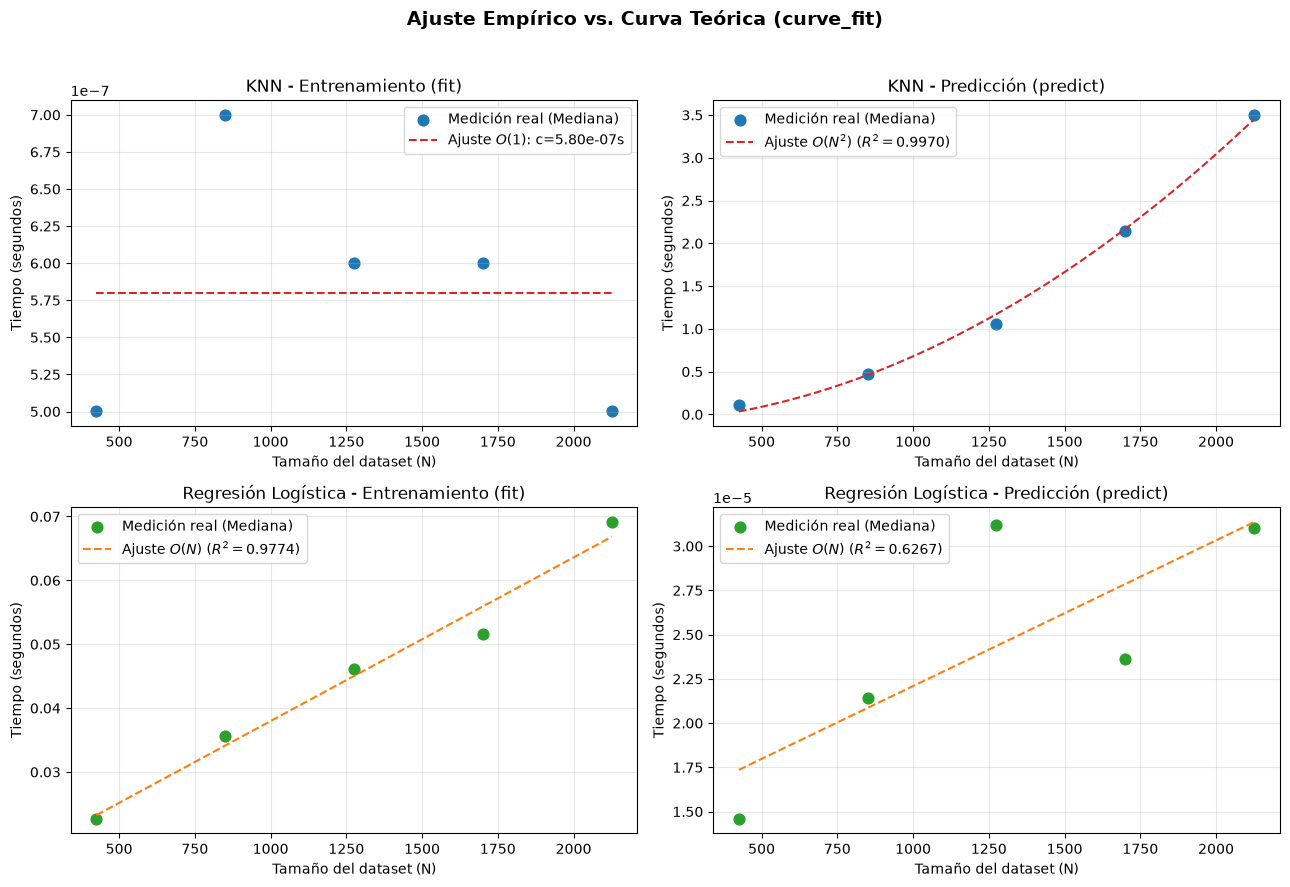

=== PARÁMETROS OBTENIDOS CON CURVE_FIT ===
KNN fit [O(1)]:          T(N) = 5.800044e-07
KNN predict [O(N^2)]:    T(N) = (7.875946e-07) * N^2 + (-1.082719e-01) | R^2 = 0.9970
Reg. Log. fit [O(N)]:    T(N) = (2.561902e-05) * N + (1.235155e-02) | R^2 = 0.9774
Reg. Log. predict [O(N)]:T(N) = (8.231228e-09) * N + (1.386356e-05) | R^2 = 0.6267


In [13]:

# 1. Definición de funciones teóricas para el ajuste
def modelo_constante(N, c):
    """Complejidad O(1)"""
    return np.full_like(N, c, dtype=float)

def modelo_lineal(N, a, b):
    """Complejidad O(N)"""
    return a * N + b

def modelo_cuadratico(N, a, b):
    """Complejidad O(N^2)"""
    return a * (N ** 2) + b

def calcular_r2(y_real, y_pred):
    """Calcula el coeficiente de determinación R^2 para evaluar la calidad del ajuste"""
    ss_res = np.sum((y_real - y_pred) ** 2)
    ss_tot = np.sum((y_real - np.mean(y_real)) ** 2)
    if ss_tot == 0:
        return 1.0
    return 1 - (ss_res / ss_tot)

# 2. Extraer ejes X (tamaño N_total) y Y (tiempos medianos) de tus resultados
N_knn = df_tiempos_knn['N_total'].to_numpy(dtype=float)
t_knn_fit = df_tiempos_knn['Fit_Mediana (s)'].to_numpy(dtype=float)
t_knn_pred = df_tiempos_knn['Predict_Mediana (s)'].to_numpy(dtype=float)

N_rl = df_tiempos_rl['N_total'].to_numpy(dtype=float)
t_rl_fit = df_tiempos_rl['Fit_Mediana (s)'].to_numpy(dtype=float)
t_rl_pred = df_tiempos_rl['Predict_Mediana (s)'].to_numpy(dtype=float)

# Eje N suave para dibujar las curvas teóricas ajustadas
N_suave = np.linspace(min(N_knn), max(N_knn), 200)

# 3. Ajustes con curve_fit
# a) KNN Fit -> O(1)
popt_knn_fit, _ = curve_fit(modelo_constante, N_knn, t_knn_fit)
curva_knn_fit = modelo_constante(N_suave, *popt_knn_fit)

# b) KNN Predict -> O(N^2)
popt_knn_pred, _ = curve_fit(modelo_cuadratico, N_knn, t_knn_pred)
curva_knn_pred = modelo_cuadratico(N_suave, *popt_knn_pred)
r2_knn_pred = calcular_r2(t_knn_pred, modelo_cuadratico(N_knn, *popt_knn_pred))

# c) Regresión Logística Fit -> O(N)
popt_rl_fit, _ = curve_fit(modelo_lineal, N_rl, t_rl_fit)
curva_rl_fit = modelo_lineal(N_suave, *popt_rl_fit)
r2_rl_fit = calcular_r2(t_rl_fit, modelo_lineal(N_rl, *popt_rl_fit))

# d) Regresión Logística Predict -> O(N) (crece linealmente porque M_test es 20% de N)
popt_rl_pred, _ = curve_fit(modelo_lineal, N_rl, t_rl_pred)
curva_rl_pred = modelo_lineal(N_suave, *popt_rl_pred)
r2_rl_pred = calcular_r2(t_rl_pred, modelo_lineal(N_rl, *popt_rl_pred))

# 4. Generación de las 4 gráficas comparativas (2x2)
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
fig.suptitle('Ajuste Empírico vs. Curva Teórica (curve_fit)', fontsize=14, fontweight='bold')

# Gráfica 1: KNN - Fit
axes[0, 0].scatter(N_knn, t_knn_fit, color='#1f77b4', s=60, label='Medición real (Mediana)')
axes[0, 0].plot(N_suave, curva_knn_fit, '--', color='#d62728', label=f'Ajuste $O(1)$: c={popt_knn_fit[0]:.2e}s')
axes[0, 0].set_title('KNN - Entrenamiento (fit)')
axes[0, 0].set_xlabel('Tamaño del dataset (N)')
axes[0, 0].set_ylabel('Tiempo (segundos)')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Gráfica 2: KNN - Predict
axes[0, 1].scatter(N_knn, t_knn_pred, color='#1f77b4', s=60, label='Medición real (Mediana)')
axes[0, 1].plot(N_suave, curva_knn_pred, '--', color='#d62728', label=f'Ajuste $O(N^2)$ ($R^2={r2_knn_pred:.4f}$)')
axes[0, 1].set_title('KNN - Predicción (predict)')
axes[0, 1].set_xlabel('Tamaño del dataset (N)')
axes[0, 1].set_ylabel('Tiempo (segundos)')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Gráfica 3: Regresión Logística - Fit
axes[1, 0].scatter(N_rl, t_rl_fit, color='#2ca02c', s=60, label='Medición real (Mediana)')
axes[1, 0].plot(N_suave, curva_rl_fit, '--', color='#ff7f0e', label=f'Ajuste $O(N)$ ($R^2={r2_rl_fit:.4f}$)')
axes[1, 0].set_title('Regresión Logística - Entrenamiento (fit)')
axes[1, 0].set_xlabel('Tamaño del dataset (N)')
axes[1, 0].set_ylabel('Tiempo (segundos)')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# Gráfica 4: Regresión Logística - Predict
axes[1, 1].scatter(N_rl, t_rl_pred, color='#2ca02c', s=60, label='Medición real (Mediana)')
axes[1, 1].plot(N_suave, curva_rl_pred, '--', color='#ff7f0e', label=f'Ajuste $O(N)$ ($R^2={r2_rl_pred:.4f}$)')
axes[1, 1].set_title('Regresión Logística - Predicción (predict)')
axes[1, 1].set_xlabel('Tamaño del dataset (N)')
axes[1, 1].set_ylabel('Tiempo (segundos)')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

# 5. Imprimir parámetros ajustados de las ecuaciones
print("=== PARÁMETROS OBTENIDOS CON CURVE_FIT ===")
print(f"KNN fit [O(1)]:          T(N) = {popt_knn_fit[0]:.6e}")
print(f"KNN predict [O(N^2)]:    T(N) = ({popt_knn_pred[0]:.6e}) * N^2 + ({popt_knn_pred[1]:.6e}) | R^2 = {r2_knn_pred:.4f}")
print(f"Reg. Log. fit [O(N)]:    T(N) = ({popt_rl_fit[0]:.6e}) * N + ({popt_rl_fit[1]:.6e}) | R^2 = {r2_rl_fit:.4f}")
print(f"Reg. Log. predict [O(N)]:T(N) = ({popt_rl_pred[0]:.6e}) * N + ({popt_rl_pred[1]:.6e}) | R^2 = {r2_rl_pred:.4f}")

## Medicion y Ajuste con libreria

Versión de scikit-learn utilizada: 1.9.1

=== RESULTADOS DE TIEMPOS: SCIKIT-LEARN KNN ===
Fraccion  N_total  N_train  M_test  Fit_Promedio (s)  Fit_Mediana (s)  Predict_Promedio (s)  Predict_Mediana (s)
     20%      425      340      85          0.001048         0.000977              0.033615             0.018075
     40%      850      680     170          0.001135         0.001070              0.028957             0.035216
     60%     1275     1020     255          0.001088         0.000900              0.026617             0.015960
     80%     1700     1360     340          0.001768         0.001999              0.002890             0.003060
    100%     2126     1700     426          0.001626         0.001658              0.003869             0.004122

=== RESULTADOS DE TIEMPOS: SCIKIT-LEARN REGRESIÓN LOGÍSTICA ===
Fraccion  N_total  N_train  M_test  Fit_Promedio (s)  Fit_Mediana (s)  Predict_Promedio (s)  Predict_Mediana (s)
     20%      425      340      85          0.019041  

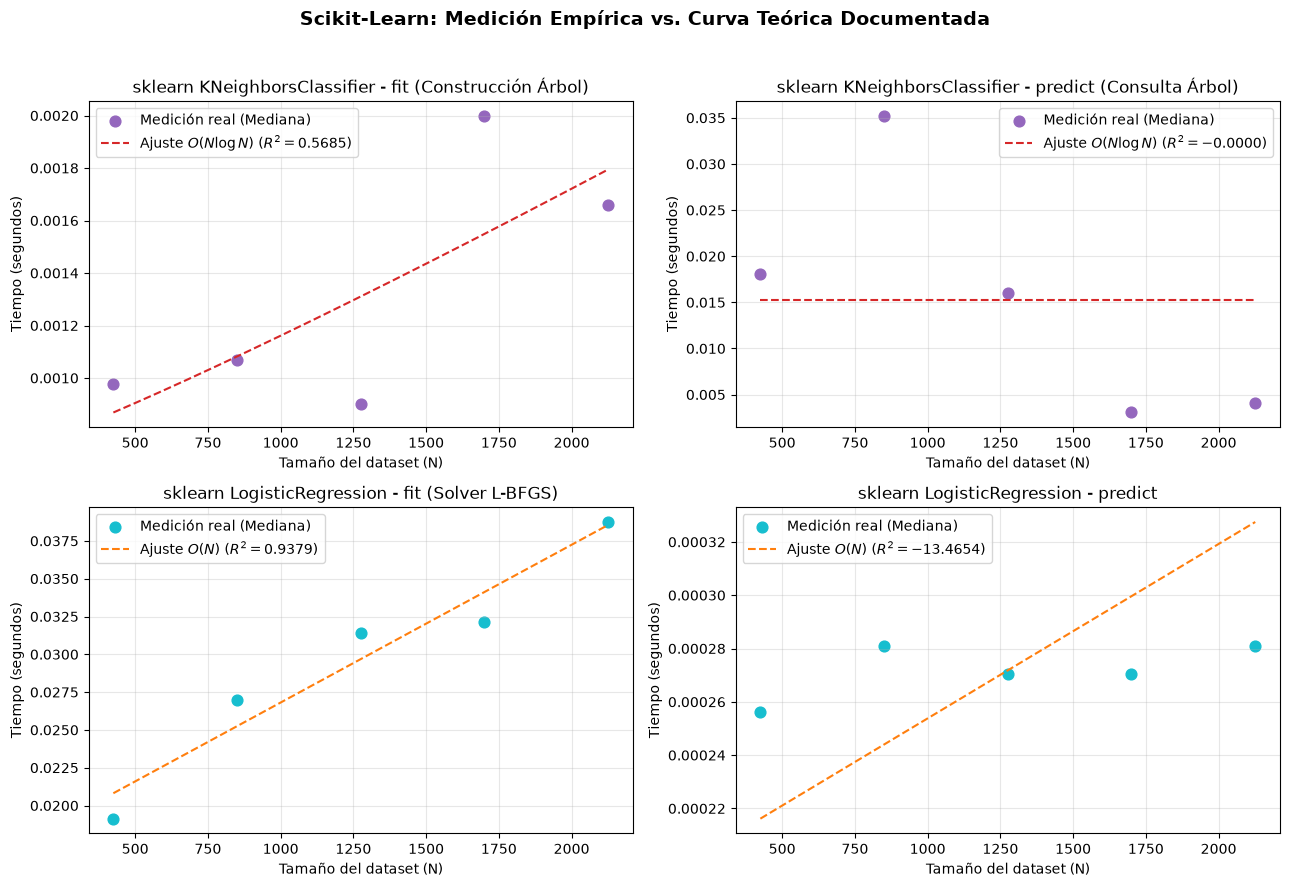


=== PARÁMETROS OBTENIDOS CON CURVE_FIT (SCIKIT-LEARN) ===
sklearn KNN fit [O(N log N)]:     T(N) = (6.751684e-08) * N*log(N) + (6.948990e-04) | R^2 = 0.5685
sklearn KNN predict [O(N log N)]: T(N) = (1.954555e-13) * N*log(N) + (1.528628e-02) | R^2 = -0.0000
sklearn Reg. Log. fit [O(N)]:     T(N) = (1.043138e-05) * N + (1.638101e-02) | R^2 = 0.9379
sklearn Reg. Log. predict [O(N)]: T(N) = (6.542700e-08) * N + (1.883675e-04) | R^2 = -13.4654


In [15]:
import sklearn
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

print(f"Versión de scikit-learn utilizada: {sklearn.__version__}\n")

# 1. Medición de tiempos con scikit-learn (7 repeticiones)
# a) KNN de scikit-learn
df_sklearn_knn = medir_tiempos_modelo(
    crear_modelo_fn=lambda: KNeighborsClassifier(n_neighbors=5, algorithm='auto'),
    datasets_por_fraccion=datasets_por_fraccion,
    repeticiones=7
)

# b) Regresión Logística de scikit-learn
df_sklearn_rl = medir_tiempos_modelo(
    crear_modelo_fn=lambda: LogisticRegression(max_iter=2000),
    datasets_por_fraccion=datasets_por_fraccion,
    repeticiones=7
)

print("=== RESULTADOS DE TIEMPOS: SCIKIT-LEARN KNN ===")
print(df_sklearn_knn.to_string(index=False))

print("\n=== RESULTADOS DE TIEMPOS: SCIKIT-LEARN REGRESIÓN LOGÍSTICA ===")
print(df_sklearn_rl.to_string(index=False))

# 2. Funciones teóricas según la documentación oficial de scikit-learn
def modelo_nlogn(N, a, b):
    """Complejidad O(N log N) para construcción y consulta en KD-Tree / Ball-Tree"""
    return a * N * np.log(N) + b

def modelo_lineal(N, a, b):
    """Complejidad O(N) para L-BFGS fit y predicción matricial"""
    return a * N + b

def calcular_r2(y_real, y_pred):
    ss_res = np.sum((y_real - y_pred) ** 2)
    ss_tot = np.sum((y_real - np.mean(y_real)) ** 2)
    return 1.0 if ss_tot == 0 else 1 - (ss_res / ss_tot)

# 3. Extraer datos y realizar ajustes con curve_fit
N_sk_knn = df_sklearn_knn['N_total'].to_numpy(dtype=float)
t_sk_knn_fit = df_sklearn_knn['Fit_Mediana (s)'].to_numpy(dtype=float)
t_sk_knn_pred = df_sklearn_knn['Predict_Mediana (s)'].to_numpy(dtype=float)

N_sk_rl = df_sklearn_rl['N_total'].to_numpy(dtype=float)
t_sk_rl_fit = df_sklearn_rl['Fit_Mediana (s)'].to_numpy(dtype=float)
t_sk_rl_pred = df_sklearn_rl['Predict_Mediana (s)'].to_numpy(dtype=float)

N_suave = np.linspace(min(N_sk_knn), max(N_sk_knn), 200)
cotas_2param = ([0.0, -np.inf], [np.inf, np.inf])

# Ajustes KNN (scikit-learn) -> O(N log N)
popt_sk_knn_fit, _ = curve_fit(modelo_nlogn, N_sk_knn, t_sk_knn_fit, bounds=cotas_2param)
curva_sk_knn_fit = modelo_nlogn(N_suave, *popt_sk_knn_fit)
r2_sk_knn_fit = calcular_r2(t_sk_knn_fit, modelo_nlogn(N_sk_knn, *popt_sk_knn_fit))

popt_sk_knn_pred, _ = curve_fit(modelo_nlogn, N_sk_knn, t_sk_knn_pred, bounds=cotas_2param)
curva_sk_knn_pred = modelo_nlogn(N_suave, *popt_sk_knn_pred)
r2_sk_knn_pred = calcular_r2(t_sk_knn_pred, modelo_nlogn(N_sk_knn, *popt_sk_knn_pred))

# Ajustes Regresión Logística (scikit-learn) -> O(N)
popt_sk_rl_fit, _ = curve_fit(modelo_lineal, N_sk_rl, t_sk_rl_fit, bounds=cotas_2param)
curva_sk_rl_fit = modelo_lineal(N_suave, *popt_sk_rl_fit)
r2_sk_rl_fit = calcular_r2(t_sk_rl_fit, modelo_lineal(N_sk_rl, *popt_sk_rl_fit))

popt_sk_rl_pred, _ = curve_fit(modelo_lineal, N_sk_rl, t_sk_rl_pred, bounds=cotas_2param)
curva_sk_rl_pred = modelo_lineal(N_suave, *popt_sk_rl_pred)
r2_sk_rl_pred = calcular_r2(t_sk_rl_pred, modelo_lineal(N_sk_rl, *popt_sk_rl_pred))

# 4. Visualización (2x2)
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
fig.suptitle('Scikit-Learn: Medición Empírica vs. Curva Teórica Documentada', fontsize=14, fontweight='bold')

# Gráfica 1: sklearn KNN - Fit
axes[0, 0].scatter(N_sk_knn, t_sk_knn_fit, color='#9467bd', s=60, label='Medición real (Mediana)')
axes[0, 0].plot(N_suave, curva_sk_knn_fit, '--', color='#d62728', label=f'Ajuste $O(N \\log N)$ ($R^2={r2_sk_knn_fit:.4f}$)')
axes[0, 0].set_title('sklearn KNeighborsClassifier - fit (Construcción Árbol)')
axes[0, 0].set_xlabel('Tamaño del dataset (N)')
axes[0, 0].set_ylabel('Tiempo (segundos)')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Gráfica 2: sklearn KNN - Predict
axes[0, 1].scatter(N_sk_knn, t_sk_knn_pred, color='#9467bd', s=60, label='Medición real (Mediana)')
axes[0, 1].plot(N_suave, curva_sk_knn_pred, '--', color='#d62728', label=f'Ajuste $O(N \\log N)$ ($R^2={r2_sk_knn_pred:.4f}$)')
axes[0, 1].set_title('sklearn KNeighborsClassifier - predict (Consulta Árbol)')
axes[0, 1].set_xlabel('Tamaño del dataset (N)')
axes[0, 1].set_ylabel('Tiempo (segundos)')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Gráfica 3: sklearn LogisticRegression - Fit
axes[1, 0].scatter(N_sk_rl, t_sk_rl_fit, color='#17becf', s=60, label='Medición real (Mediana)')
axes[1, 0].plot(N_suave, curva_sk_rl_fit, '--', color='#ff7f0e', label=f'Ajuste $O(N)$ ($R^2={r2_sk_rl_fit:.4f}$)')
axes[1, 0].set_title('sklearn LogisticRegression - fit (Solver L-BFGS)')
axes[1, 0].set_xlabel('Tamaño del dataset (N)')
axes[1, 0].set_ylabel('Tiempo (segundos)')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# Gráfica 4: sklearn LogisticRegression - Predict
axes[1, 1].scatter(N_sk_rl, t_sk_rl_pred, color='#17becf', s=60, label='Medición real (Mediana)')
axes[1, 1].plot(N_suave, curva_sk_rl_pred, '--', color='#ff7f0e', label=f'Ajuste $O(N)$ ($R^2={r2_sk_rl_pred:.4f}$)')
axes[1, 1].set_title('sklearn LogisticRegression - predict')
axes[1, 1].set_xlabel('Tamaño del dataset (N)')
axes[1, 1].set_ylabel('Tiempo (segundos)')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

# 5. Imprimir parámetros ajustados de las ecuaciones
print("\n=== PARÁMETROS OBTENIDOS CON CURVE_FIT (SCIKIT-LEARN) ===")
print(f"sklearn KNN fit [O(N log N)]:     T(N) = ({popt_sk_knn_fit[0]:.6e}) * N*log(N) + ({popt_sk_knn_fit[1]:.6e}) | R^2 = {r2_sk_knn_fit:.4f}")
print(f"sklearn KNN predict [O(N log N)]: T(N) = ({popt_sk_knn_pred[0]:.6e}) * N*log(N) + ({popt_sk_knn_pred[1]:.6e}) | R^2 = {r2_sk_knn_pred:.4f}")
print(f"sklearn Reg. Log. fit [O(N)]:     T(N) = ({popt_sk_rl_fit[0]:.6e}) * N + ({popt_sk_rl_fit[1]:.6e}) | R^2 = {r2_sk_rl_fit:.4f}")
print(f"sklearn Reg. Log. predict [O(N)]: T(N) = ({popt_sk_rl_pred[0]:.6e}) * N + ({popt_sk_rl_pred[1]:.6e}) | R^2 = {r2_sk_rl_pred:.4f}")

### Optimizacion  de Scikit-learn e impacto 

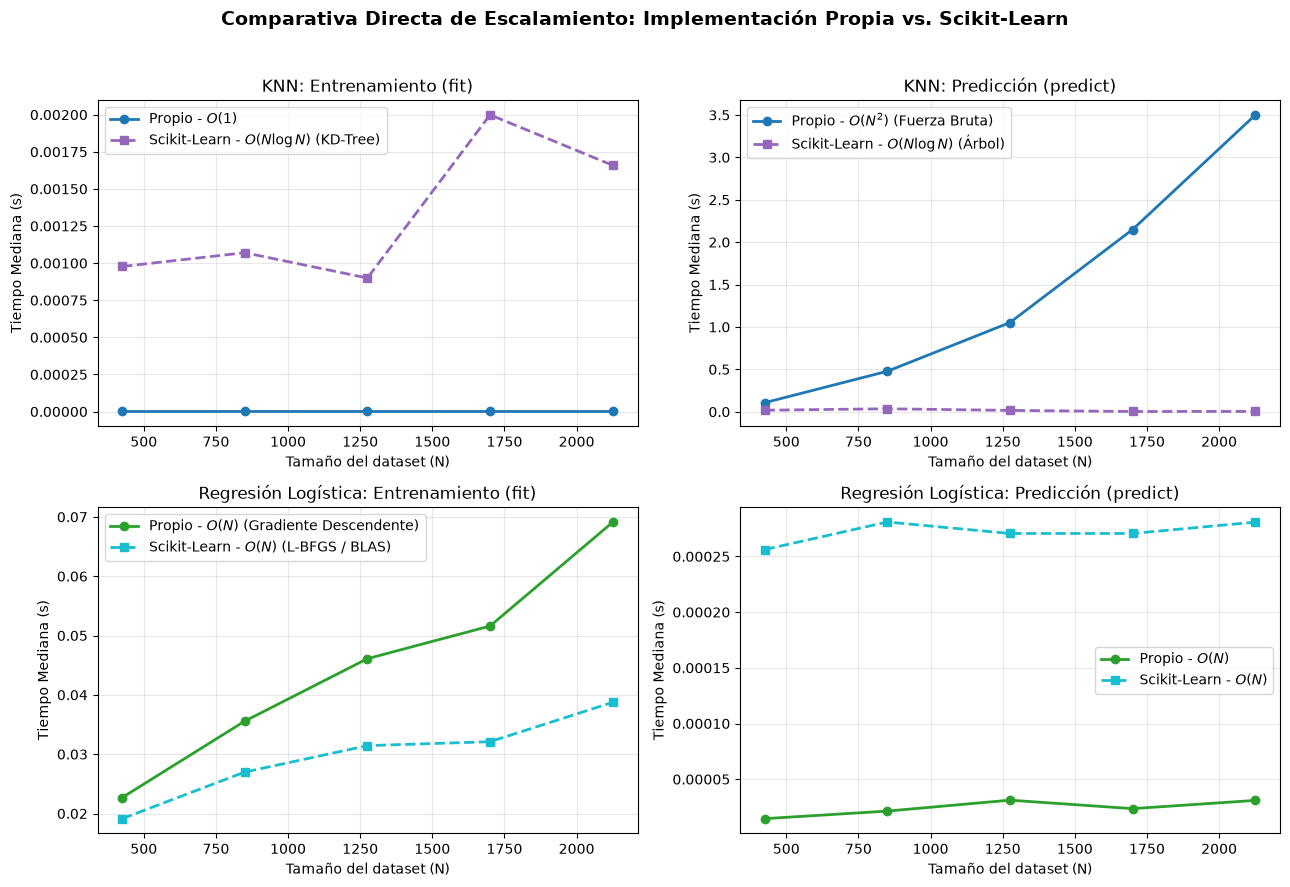

In [16]:


# Extraer tamaños N y tiempos medianos (Propio vs. Scikit-Learn)
N = df_tiempos_knn['N_total'].to_numpy(dtype=float)

# KNN
knn_propio_fit = df_tiempos_knn['Fit_Mediana (s)'].to_numpy(dtype=float)
knn_sk_fit = df_sklearn_knn['Fit_Mediana (s)'].to_numpy(dtype=float)

knn_propio_pred = df_tiempos_knn['Predict_Mediana (s)'].to_numpy(dtype=float)
knn_sk_pred = df_sklearn_knn['Predict_Mediana (s)'].to_numpy(dtype=float)

# Regresión Logística
rl_propio_fit = df_tiempos_rl['Fit_Mediana (s)'].to_numpy(dtype=float)
rl_sk_fit = df_sklearn_rl['Fit_Mediana (s)'].to_numpy(dtype=float)

rl_propio_pred = df_tiempos_rl['Predict_Mediana (s)'].to_numpy(dtype=float)
rl_sk_pred = df_sklearn_rl['Predict_Mediana (s)'].to_numpy(dtype=float)

# Gráfica comparativa directa (2x2)
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
fig.suptitle('Comparativa Directa de Escalamiento: Implementación Propia vs. Scikit-Learn', fontsize=14, fontweight='bold')

# 1. KNN - Fit
axes[0, 0].plot(N, knn_propio_fit, 'o-', color='#1f77b4', linewidth=2, label='Propio - $O(1)$')
axes[0, 0].plot(N, knn_sk_fit, 's--', color='#9467bd', linewidth=2, label='Scikit-Learn - $O(N \\log N)$ (KD-Tree)')
axes[0, 0].set_title('KNN: Entrenamiento (fit)')
axes[0, 0].set_xlabel('Tamaño del dataset (N)')
axes[0, 0].set_ylabel('Tiempo Mediana (s)')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# 2. KNN - Predict
axes[0, 1].plot(N, knn_propio_pred, 'o-', color='#1f77b4', linewidth=2, label='Propio - $O(N^2)$ (Fuerza Bruta)')
axes[0, 1].plot(N, knn_sk_pred, 's--', color='#9467bd', linewidth=2, label='Scikit-Learn - $O(N \\log N)$ (Árbol)')
axes[0, 1].set_title('KNN: Predicción (predict)')
axes[0, 1].set_xlabel('Tamaño del dataset (N)')
axes[0, 1].set_ylabel('Tiempo Mediana (s)')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# 3. Regresión Logística - Fit
axes[1, 0].plot(N, rl_propio_fit, 'o-', color='#2ca02c', linewidth=2, label='Propio - $O(N)$ (Gradiente Descendente)')
axes[1, 0].plot(N, rl_sk_fit, 's--', color='#17becf', linewidth=2, label='Scikit-Learn - $O(N)$ (L-BFGS / BLAS)')
axes[1, 0].set_title('Regresión Logística: Entrenamiento (fit)')
axes[1, 0].set_xlabel('Tamaño del dataset (N)')
axes[1, 0].set_ylabel('Tiempo Mediana (s)')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# 4. Regresión Logística - Predict
axes[1, 1].plot(N, rl_propio_pred, 'o-', color='#2ca02c', linewidth=2, label='Propio - $O(N)$')
axes[1, 1].plot(N, rl_sk_pred, 's--', color='#17becf', linewidth=2, label='Scikit-Learn - $O(N)$')
axes[1, 1].set_title('Regresión Logística: Predicción (predict)')
axes[1, 1].set_xlabel('Tamaño del dataset (N)')
axes[1, 1].set_ylabel('Tiempo Mediana (s)')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

### Análisis de Optimizaciones e Impacto en el Escalamiento (Propio vs. `scikit-learn`)

#### 1. KNN (`KNNClassifier` vs. `KNeighborsClassifier`)
* **Cambio en el Orden Asintótico (Estructuras de Datos Espaciales):**
  * **Implementación Propia:** Emplea fuerza bruta (*brute-force*). El método `fit` es $O(1)$ porque únicamente guarda referencias en memoria, pero `predict` escala de forma cuadrática **$O(N^2)$** al calcular la distancia euclidiana de cada punto de prueba contra todos los puntos de entrenamiento.
  * **`scikit-learn`:** Indexa los datos durante `fit` mediante árboles particionadores del espacio (**KD-Tree** o **Ball-Tree**), invirtiendo un costo inicial de construcción de **$O(N \log N)$**. Esto permite podar ramas enteras del espacio durante `predict`, reduciendo el orden asintótico de búsqueda a **$O(N \log N)$** y evitando la explosión cuadrática conforme crece $N$.
* **Reducción de la Pendiente (Bajo Nivel):** Los cálculos de distancias y ordenamientos parciales (`argpartition`) están compilados en **Cython / C++**, eliminando la sobrecarga del intérprete de Python.

#### 2. Regresión Logística (`LogisticRegression` propia vs. `sklearn.linear_model.LogisticRegression`)
* **Mismo Orden Asintótico, Menor Pendiente (Optimizadores Internos):**
  * **Implementación Propia:** Utiliza Descenso de Gradiente de primer orden (*Batch Gradient Descent*) con tasa de aprendizaje fija, requiriendo miles de iteraciones (`n_iterations=2000`) para converger, lo que produce una pendiente pronunciada en `fit` ($O(N)$).
  * **`scikit-learn`:** Emplea el optimizador cuasi-Newton **L-BFGS** (*Limited-memory Broyden–Fletcher–Goldfarb–Shanno*), el cual aproxima la matriz Hessiana (información de segunda derivada) para ajustar dinámicamente el tamaño y dirección del paso. Aunque mantiene el orden lineal **$O(N)$**, converge en una fracción de las iteraciones necesarias para el gradiente estándar.
* **Vectorización y Álgebra Lineal:** Internamente delega las multiplicaciones matriciales a librerías **BLAS/LAPACK** multihilo en C/Fortran, reduciendo drásticamente las constantes multiplicativas tanto en `fit` como en `predict`.